# EuroSAT Land-Cover Classification — A Comparative Deep Learning Study with Transfer Learning

## Notebook 01 — Dataset Audit & Exploration

## Notebook Goal

Before building any data pipeline or training any model, we need to understand and verify the dataset we are working with.

This notebook checks:

- Whether the dataset folder structure matches what we expect
- How many images each class actually contains, and whether the classes are balanced
- Whether the image files are readable, in the expected format (JPEG), size (64×64), and color mode (RGB)
- What the classes actually look like, through a small set of representative images

No model training, splitting, augmentation, or normalization happens here. Skipping this step and going straight to modeling is a common source of silent bugs (wrong labels, corrupted files, unexpected image sizes), so we verify everything first.

## Imports

In [1]:
from pathlib import Path
from collections import Counter
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

## Configuration

In [ ]:
DATASET_ROOT = Path("data/EuroSAT_RGB")

CLASS_NAMES = [
    "AnnualCrop", "Forest", "HerbaceousVegetation",
    "Highway", "Industrial", "Pasture",
    "PermanentCrop", "Residential", "River",
    "SeaLake",
]

EXPECTED_TOTAL_IMAGES = 27000
EXPECTED_IMAGE_SIZE = (64, 64)
EXPECTED_IMAGE_MODE = "RGB"
EXPECTED_EXTENSIONS = {".jpg", ".jpeg"}

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

## Dataset Existence and Folder Audit

First, we check that the dataset path exists and that the folder structure matches the 10 expected classes, before trusting anything else about the data.

In [3]:
assert DATASET_ROOT.exists(), f"Dataset path does not exist: {DATASET_ROOT}"
assert DATASET_ROOT.is_dir(), f"Dataset path is not a directory: {DATASET_ROOT}"

found_folders = sorted(p.name for p in DATASET_ROOT.iterdir() if p.is_dir())

missing_classes = sorted(set(CLASS_NAMES) - set(found_folders))
unexpected_folders = sorted(set(found_folders) - set(CLASS_NAMES))

folder_structure_valid = (not missing_classes) and (not unexpected_folders)

print(f"Dataset root: {DATASET_ROOT}")
print(f"Folders found: {len(found_folders)}")
print(f"Missing expected class folders: {missing_classes if missing_classes else 'None'}")
print(f"Unexpected folders: {unexpected_folders if unexpected_folders else 'None'}")
print(f"\nFolder structure valid: {folder_structure_valid}")

Dataset root: data\EuroSAT_RGB
Folders found: 10
Missing expected class folders: None
Unexpected folders: None

Folder structure valid: True


## File Inventory

Next, we inventory each class folder in two steps: first every file inside it, then only the files that are actual JPEG images (by extension). Image counts and later checks use only the image files; the extension audit below uses every file, so a stray non-image file isn't silently ignored.

In [ ]:
def list_class_files(class_dir: Path):
    
    return [p for p in class_dir.iterdir() if p.is_file()]

class_all_files = {
    class_name: list_class_files(DATASET_ROOT / class_name)
    for class_name in CLASS_NAMES
}

class_image_paths = {
    class_name: [p for p in files if p.suffix.lower() in EXPECTED_EXTENSIONS]
    for class_name, files in class_all_files.items()
}

class_counts = {name: len(paths) for name, paths in class_image_paths.items()}

counts_df = pd.DataFrame(
    sorted(class_counts.items()), columns=["class_name", "num_images"]
)

total_images = int(counts_df["num_images"].sum())
total_files = sum(len(files) for files in class_all_files.values())

print(counts_df.to_string(index=False))
print(f"\nTotal image files (JPEG) found: {total_images}")
print(f"Total files found (any type): {total_files}")
print(f"Expected total images: {EXPECTED_TOTAL_IMAGES}")
print(f"Difference from expected: {total_images - EXPECTED_TOTAL_IMAGES}")

          class_name  num_images
          AnnualCrop        3000
              Forest        3000
HerbaceousVegetation        3000
             Highway        2500
          Industrial        2500
             Pasture        2000
       PermanentCrop        2500
         Residential        3000
               River        2500
             SeaLake        3000

Total image files (JPEG) found: 27000
Total files found (any type): 27000
Expected total images: 27000
Difference from expected: 0


## File Type Check

We check the extensions of every file found (not just the ones already counted as images) and confirm they match the expected JPEG format.

In [5]:
all_extensions = Counter()
for files in class_all_files.values():
    for p in files:
        all_extensions[p.suffix.lower()] += 1

print("File extensions found in the dataset (all files):")
for ext, count in all_extensions.most_common():
    print(f"  {ext or '(no extension)'}: {count}")

unexpected_extensions = {
    ext: count for ext, count in all_extensions.items() if ext not in EXPECTED_EXTENSIONS
}
print(f"\nUnexpected file extensions: {unexpected_extensions if unexpected_extensions else 'None'}")

File extensions found in the dataset (all files):
  .jpg: 27000

Unexpected file extensions: None


## Image Integrity Check

We open every image once to verify it isn't corrupted, and once more to check its size and color mode. Images are processed one at a time (never all loaded into memory together) since there are 27,000 of them.

In [ ]:
corrupted_files = []
size_violations = []
mode_violations = []
checked_count = 0

for class_name, paths in class_image_paths.items():
    for path in paths:
        checked_count += 1

        try:
            with Image.open(path) as img:
                img.verify()
        except Exception as e:
            corrupted_files.append((str(path), str(e)))
            continue

        try:
            with Image.open(path) as img:
                if img.size != EXPECTED_IMAGE_SIZE:
                    size_violations.append((str(path), img.size))
                if img.mode != EXPECTED_IMAGE_MODE:
                    mode_violations.append((str(path), img.mode))
        except Exception as e:
            corrupted_files.append((str(path), str(e)))

print(f"Images checked: {checked_count}")
print(f"Corrupted / unreadable images: {len(corrupted_files)}")
print(f"Images with unexpected size (expected {EXPECTED_IMAGE_SIZE}): {len(size_violations)}")
print(f"Images with unexpected mode (expected \'{EXPECTED_IMAGE_MODE}\'): {len(mode_violations)}")

if corrupted_files:
    print("\nFirst few corrupted files:")
    for path, err in corrupted_files[:5]:
        print(f"  {path}: {err}")

if size_violations:
    print("\nFirst few size violations:")
    for path, size in size_violations[:5]:
        print(f"  {path}: {size}")

if mode_violations:
    print("\nFirst few mode violations:")
    for path, mode in mode_violations[:5]:
        print(f"  {path}: {mode}")

Images checked: 27000
Corrupted / unreadable images: 0
Images with unexpected size (expected (64, 64)): 0
Images with unexpected mode (expected 'RGB'): 0


## Dataset Statistics

A short numeric summary of class balance, computed from the counts above.

In [7]:
num_classes = len(class_counts)
min_row = counts_df.loc[counts_df["num_images"].idxmin()]
max_row = counts_df.loc[counts_df["num_images"].idxmax()]
class_count_diff = int(max_row["num_images"] - min_row["num_images"])
balance_ratio = max_row["num_images"] / min_row["num_images"]

print(f"Total images: {total_images}")
print(f"Number of classes: {num_classes}")
print(f"Smallest class: {min_row['class_name']} ({min_row['num_images']} images)")
print(f"Largest class: {max_row['class_name']} ({max_row['num_images']} images)")
print(f"Class count difference (max - min): {class_count_diff}")
print(f"Largest/smallest ratio: {balance_ratio:.2f}")

Total images: 27000
Number of classes: 10
Smallest class: Pasture (2000 images)
Largest class: AnnualCrop (3000 images)
Class count difference (max - min): 1000
Largest/smallest ratio: 1.50


## Class Distribution Visualization

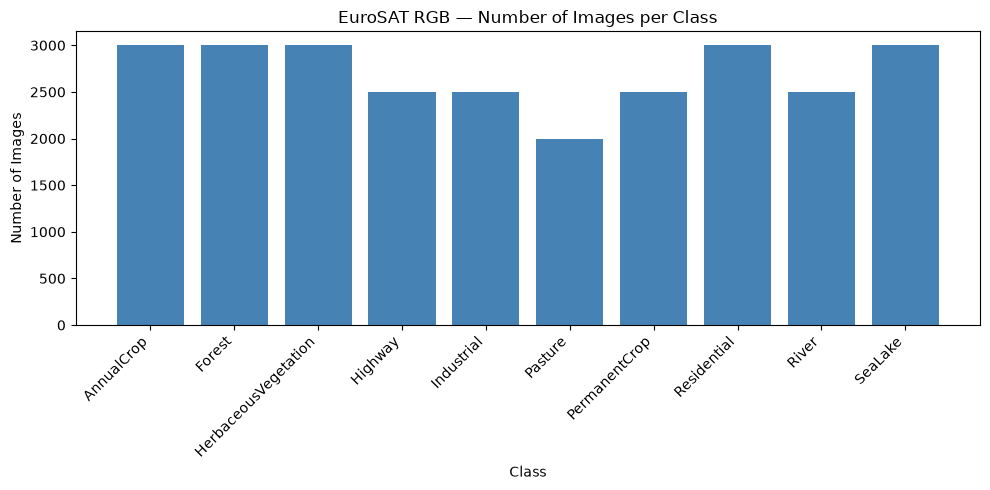

In [8]:
plt.figure(figsize=(10, 5))
plt.bar(counts_df["class_name"], counts_df["num_images"], color="steelblue")
plt.title("EuroSAT RGB — Number of Images per Class")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Representative Images

One randomly selected image per class, sampled reproducibly with `SEED = 42`, just to see what each class actually looks like.

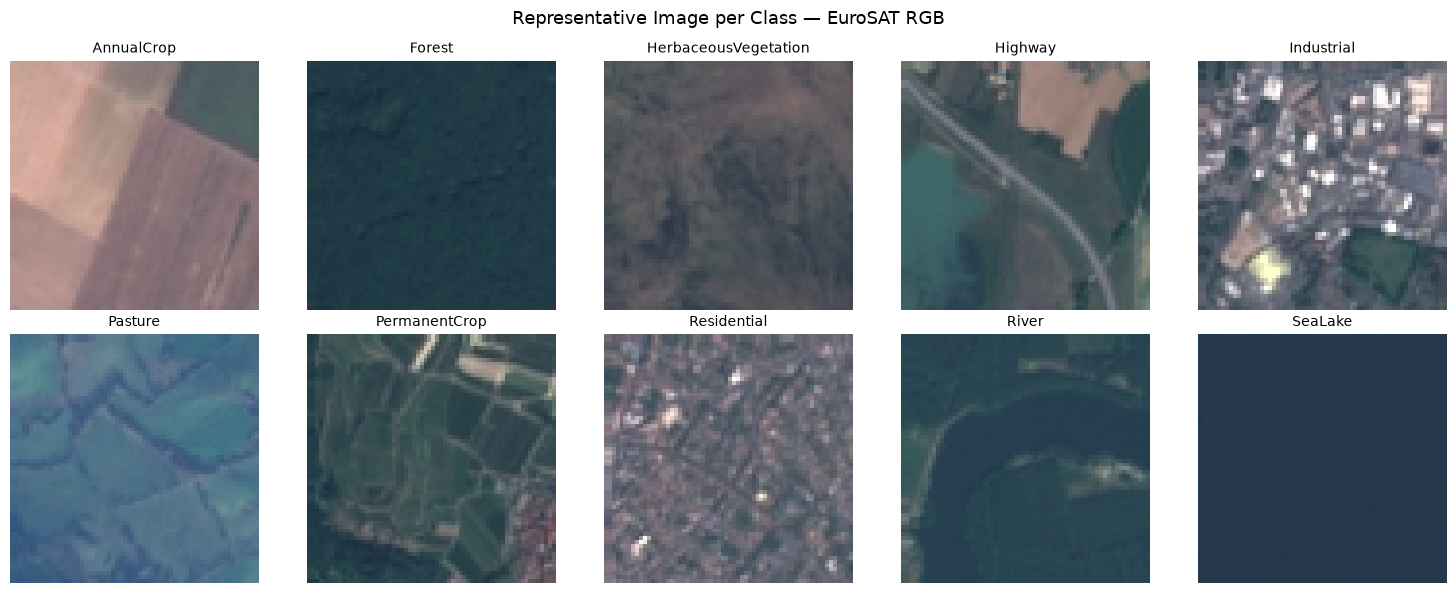

In [ ]:
rng = random.Random(SEED)

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()

for ax, class_name in zip(axes, CLASS_NAMES):
    sample_path = rng.choice(class_image_paths[class_name])
    with Image.open(sample_path) as img:
        ax.imshow(img)
    ax.set_title(class_name, fontsize=10)
    ax.axis("off")
    
plt.suptitle("Representative Image per Class — EuroSAT RGB", fontsize=13)
plt.tight_layout()
plt.show()

## Basic Visual Observations

Based only on the ten sampled images above (one per class), so these are impressions from a very small sample, not conclusions about the whole dataset or about how any model will perform:

- **Field-like classes:** AnnualCrop shows large smooth tan/brown parcels; PermanentCrop shows a patchwork of smaller dark-green parcels with light paths; Pasture appears as a blue-green tone with darker boundary lines between fields; HerbaceousVegetation appears as a mottled brownish-gray texture without clear parcel edges. These four look like variations of agricultural or vegetated land and share similar color tones, so they look the most similar to one another.
- **Dark, low-texture classes:** Forest (uniform dark green) and SeaLake (almost uniform dark blue, with very little visible texture) have little visible structure at this resolution.
- **Linear/water features:** Highway shows a gray strip crossing the frame, next to fields and a teal water patch; River shows a dark curved water band beside vegetation. Both are dominated by a long, narrow or curved feature on a darker background.
- **Built-up classes:** Industrial (bright rectangular building footprints mixed with some green) and Residential (a dense, regular pattern of small buildings and streets) are visually distinct from the vegetation classes in this sample.

The images are only 64×64 pixels, so fine detail is limited.


## Audit Summary

A side-by-side view of expected vs. observed values, computed from the checks above.

In [ ]:
jpeg_breakdown = ", ".join(
    f"{ext}: {count:,}" for ext, count in sorted(all_extensions.items()) if ext in EXPECTED_EXTENSIONS
)
observed_file_type = jpeg_breakdown if jpeg_breakdown else "None found"
if unexpected_extensions:
    unexpected_breakdown = ", ".join(
        f"{ext or '(no extension)'}: {count:,}" for ext, count in sorted(unexpected_extensions.items())
    )
    observed_file_type += f" | unexpected: {unexpected_breakdown}"

summary_df = pd.DataFrame(
    [
        ["Dataset path", str(DATASET_ROOT), str(DATASET_ROOT)],
        ["Total images", EXPECTED_TOTAL_IMAGES, total_images],
        ["Number of classes", len(CLASS_NAMES), num_classes],
        ["Missing class folders", "None", missing_classes if missing_classes else "None"],
        ["Unexpected folders", "None", unexpected_folders if unexpected_folders else "None"],
        ["File type", "JPEG (.jpg / .jpeg)", observed_file_type],
        ["Image size", str(EXPECTED_IMAGE_SIZE), f"{len(size_violations)} violation(s)"],
        ["Image mode", EXPECTED_IMAGE_MODE, f"{len(mode_violations)} violation(s)"],
        ["Corrupted images", 0, len(corrupted_files)],
    ],
    columns=["Check", "Expected", "Observed"],
)
summary_df

,Check,Expected,Observed
0,Dataset path,data\EuroSAT_RGB,data\EuroSAT_RGB
1,Total images,27000,27000
2,Number of classes,10,10
3,Missing class folders,None,None
4,Unexpected folders,None,None
5,File type,JPEG (.jpg / .jpeg),".jpg: 27,000"
6,Image size,"(64, 64)",0 violation(s)
7,Image mode,RGB,0 violation(s)
8,Corrupted images,0,0


## Key Takeaways

The dataset matches every expectation checked in this notebook:

- **Structure:** all 10 expected class folders are present, with no missing or unexpected folders.
- **Size and format:** 27,000 images in total, all `.jpg` (27,000 files, no other file types).
- **Image properties:** every image opened without error (0 corrupted), is 64×64, and is in RGB mode (0 size violations, 0 mode violations).
- **Class balance:** classes range from 2,000 images (Pasture) to 3,000 images (AnnualCrop, Forest, HerbaceousVegetation, Residential, SeaLake); the largest/smallest ratio is 1.50. The imbalance is mild, but it is the reason the next notebook uses a stratified split.

Nothing needs to be resolved first, and the dataset is ready for Notebook 02 (Data Split & TensorFlow Pipeline).
